# Creating Hodograph Plots

This tutorial creates SounderPy Hodograph plots! 

#### Here we will explore:   
- Building hodographs
- Plots in dark mode
- Storm relative hodographs
- Saving hodograph plots to a file

In [1]:
# First lets import SounderPy. Its fun to import as 'spy'!
import sounderpy as spy

## Load some data to plot

Here we can load some data with SounderPy.

Let's investigate DTX (White Lake, MI) observations for a June tornado outbreak in 2015. We can use the `get_obs_data()` function to do this

In [2]:
clean_data = spy.get_obs_data('dtx', '2015', '06', '23', '00')

> OBSERVED DATA ACCESS FUNCTION
  -----------------------------------


    > PROFILE FOUND: DTX on 06/23/2015 at 00z | From UW (ID: 72632)
    > COMPLETE --------
    > RUNTIME: 00:00:06
    > SUMMARY: 00Z Launch for KDTX, White Lake at 06-23-2015-00Z


 
    > THERMODYNAMICS --------------------------------------------- 
    --- SBCAPE: 3040.2 | MUCAPE: 3040.2 | MLCAPE: 2314.7 | MUECAPE: 2846.4
    --- MU 0-3: 99.9 | MU 0-6: 845.9 | SB 0-3: 99.9 | SB 0-6: 845.9
 
    > KINEMATICS ------------------------------------------------- 
    --- 0-500 SRW: 43.3 knot | 0-500 SWV: 0.032 | 0-500 SHEAR: 28.8 | 0-500 SRH: 308.5
    --- 1-3km SRW: 33.1 knot | 1-3km SWV: 0.013 | 1-3km SHEAR: 57.3 | | 1-3km SRH: 337.1
 


## Build a full hodograph plot

Here we use the most basic version of the `build_hodograph()` function.

> HODOGRAPH PLOTTER FUNCTION --
-------------------------------
    > PREPARING DATA


    > BUILDING HODOGRAPH
    > BUILDING MAP INSET


    > RADAR SCAN FOUND: Site: KDTX Scan: 2015-06-23 | 00:04z


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


    > BUILDING ACCESSORY PLOTS
    > PLOTTING PARAMETERS
    > FIGURE LOADING...
    > COMPLETE --------
    > RUNTIME: 00:00:13


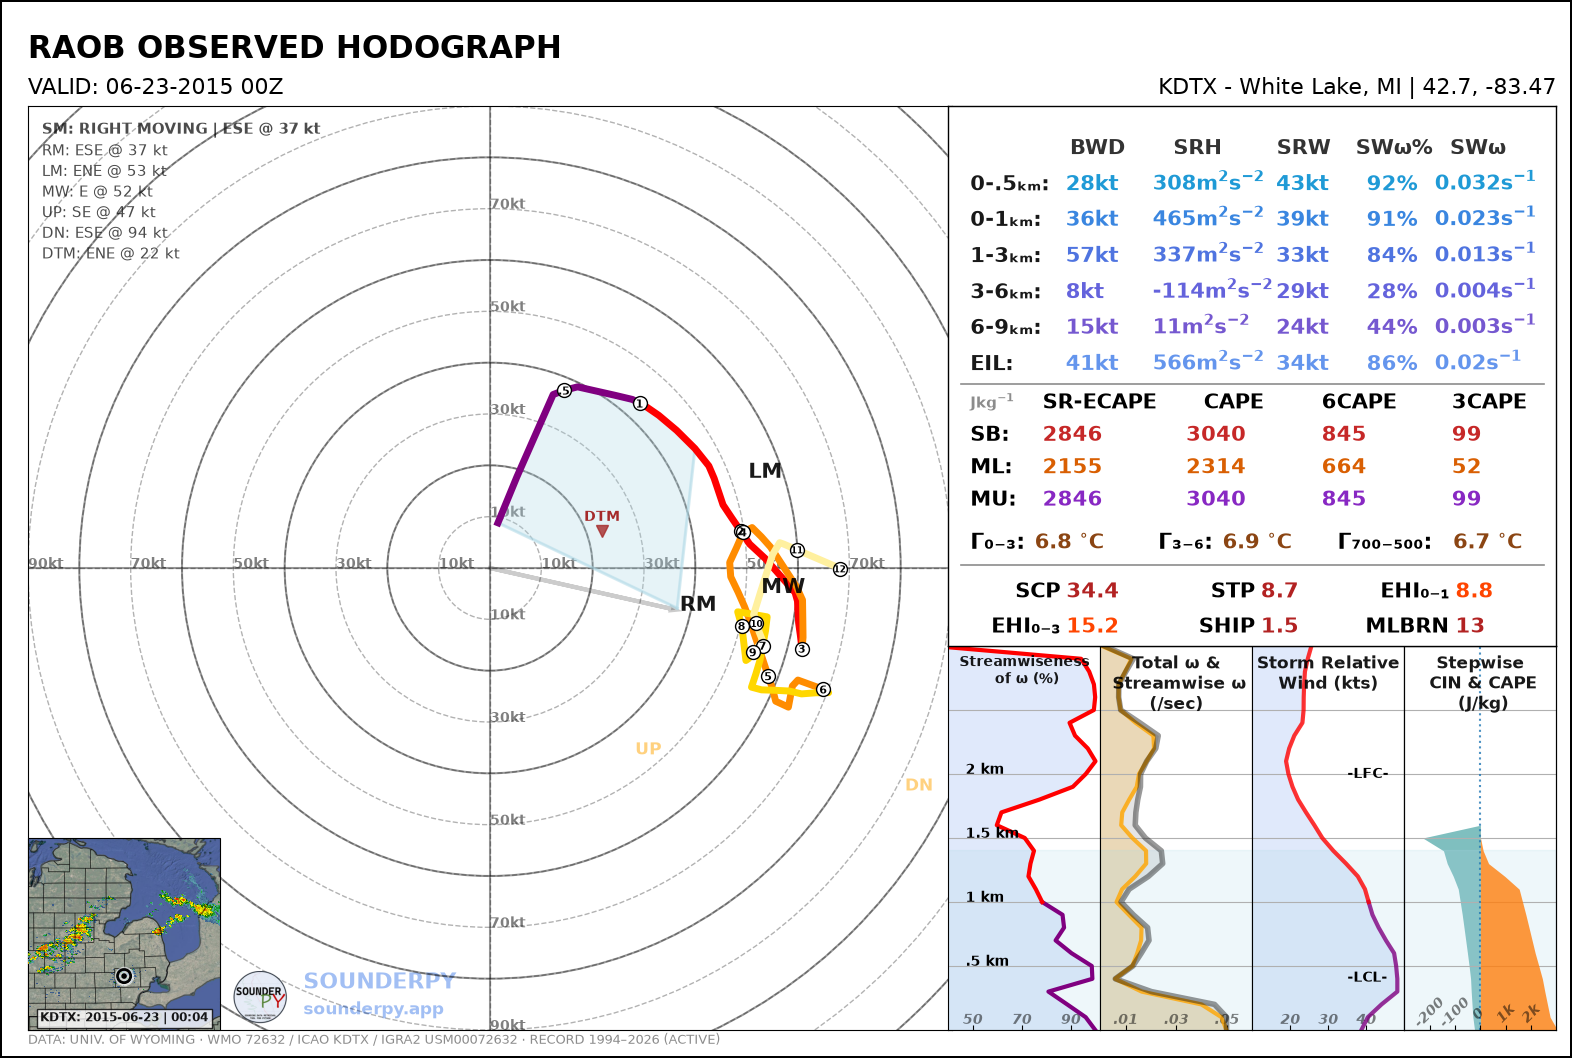

In [3]:
# light-mode hodograph
# radar='single' shows the nearest NEXRAD site's reflectivity on the map.
# The default radar mosaic only keeps about the last month, so it can't cover this date.
spy.build_hodograph(clean_data, radar='single')

## Playing with hodograph settings

The plot above requried a very simple line of code. 

Now we can adjust a few settings to customize the plot a little bit.

To do so, let's first study the `build_hodograph()` function...

#### `build_hodograph(clean_data, dark_mode=False, storm_motion='right_moving', sr_hodo=False, modify_sfc=None, radar='mosaic', radar_time='sounding', map_zoom=2, hodo_boundary=None, dpi=100, save=False, filename='sounderpy_hodograph', max_levels=250, theme=None)`

where:

- `clean_data` (dict, required) – the dictionary of data to be plotted

- `dark_mode` (bool, optional, default is False) – True will invert the color scheme for a 'dark-mode' hodograph.

- `storm_motion` (str or list of floats, optional, default is 'right_moving') – the storm motion used for plotting and calculations. Custom storm motions are accepted as a list of floats representing direction and speed. Ex: [270.0, 25.0] where '270.0' is the direction in degrees and '25.0' is the speed in kts. See the documentation for more details.

- `sr_hodo` (bool, optional, default is False) – transform the hodograph from ground relative to storm relative

- `modify_sfc` (None or dict, optional, default is None) – a `dict` in the format `{'T': 25, 'Td': 21, 'ws': 20, 'wd': 270}` to modify the surface values of the `clean_data` dict. See the documentation for more details.

- `radar` (str or None, optional, default is 'mosaic') – the radar shown on the map inset: 'mosaic', 'single' (the nearest NEXRAD site), or None. **Note: radar mosaic data only goes back about 1 month from the current date, so use 'single' for older cases.**

- `radar_time` (str or datetime, optional, default is 'sounding') – radar valid time: 'sounding', 'now', or a `datetime`.

- `map_zoom` (int, optional, default is 2) – a 'zoom' level for the map inset. **Note: setting `map_zoom=0` will hide the map**

- `hodo_boundary` (dict, optional) – draw one or more 'boundary' lines on the hodograph, given as angles and colors.

- `dpi` (int, optional, default is 100) – resolution of the figure.

- `save` (bool, optional, default is False) – whether to show the plot inline or save to a file.

- `filename` (str, optional, default is 'sounderpy_hodograph') – the filename to save to if `save=True`.

- `max_levels` (int or None, optional, default is 250) – the most vertical levels used; longer profiles are thinned. None uses every level.

- `theme` (dict, optional) – changes to the figure's colors, such as `{'border': 'k'}`.

See every option in detail: *https://kylejgillett.github.io/sounderpy/reference/plottingdata.html#building-hodographs*

This case is from 2015, older than the radar mosaic archive, so the examples below use `radar='single'` to show reflectivity from the nearest NEXRAD site.



Lets try the `dark_mode` setting:

> HODOGRAPH PLOTTER FUNCTION --
-------------------------------
    > PREPARING DATA


    > BUILDING HODOGRAPH
    > BUILDING MAP INSET


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


    > RADAR SCAN FOUND: Site: KDTX Scan: 2015-06-23 | 00:04z
    > BUILDING ACCESSORY PLOTS


    > PLOTTING PARAMETERS
    > FIGURE LOADING...
    > COMPLETE --------
    > RUNTIME: 00:00:04


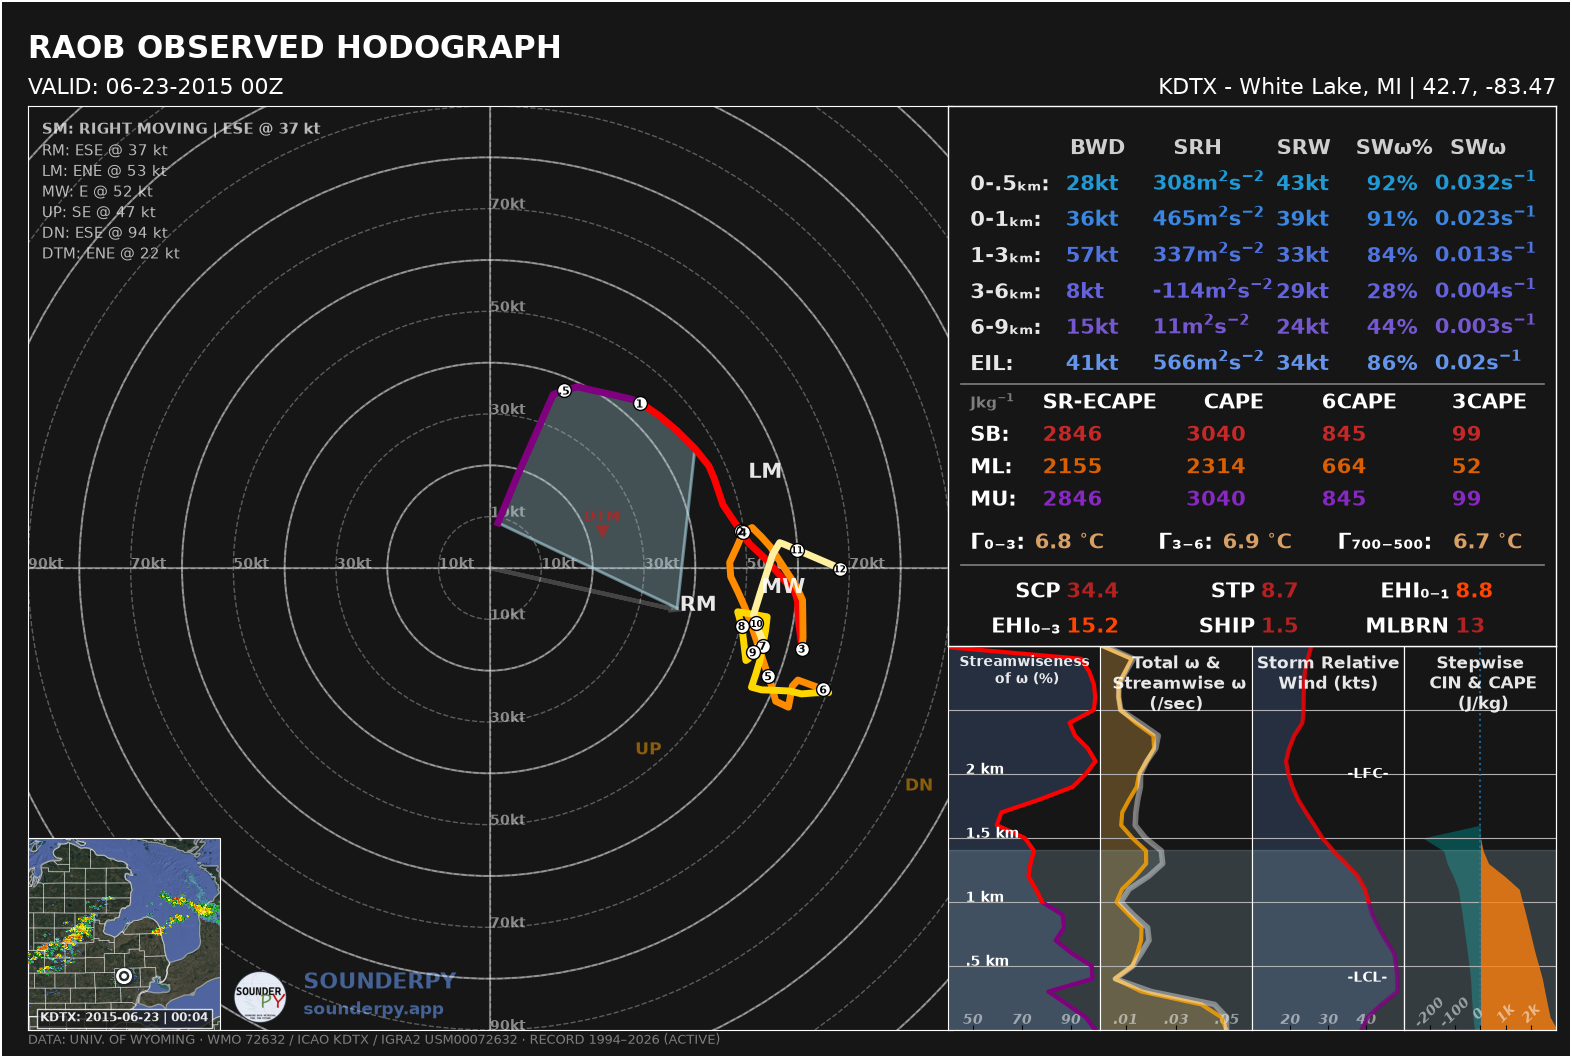

In [4]:
# dark_mode turned on!
spy.build_hodograph(clean_data, dark_mode=True, radar='single')

## Storm relative hodographs

A storm-relative hodograph is a hodograph centered on the storm-motion. In this way we can think more about what the "storm feels". 

A storm-relative hodograph "normalizes all of the seemingly-infinite hodograph shapes into what the supercell actually experiences" - Cameron J Nixon (read more here: https://cameronjnixon.wordpress.com/research/hodographs/)

To create a SounderPy storm relative hodograph, simply use the `sr_hodo` kwarg, set it equl to `True`. 

**NOTE**
- This will only work if a storm motion exists. 
- The storm motion defaults to Bunkers Right Moving, but this can be changed with the `storm_motion` kwarg.
- A vertical profile must be over 6km tall for the Bunkers calculation to work, so profiles below this height will still be 'ground-relative'

> HODOGRAPH PLOTTER FUNCTION --
-------------------------------
    > PREPARING DATA


    > BUILDING HODOGRAPH
    > BUILDING MAP INSET


    > RADAR SCAN FOUND: Site: KDTX Scan: 2015-06-23 | 00:04z


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


    > BUILDING ACCESSORY PLOTS
    > PLOTTING PARAMETERS
    > FIGURE LOADING...
    > COMPLETE --------
    > RUNTIME: 00:00:03


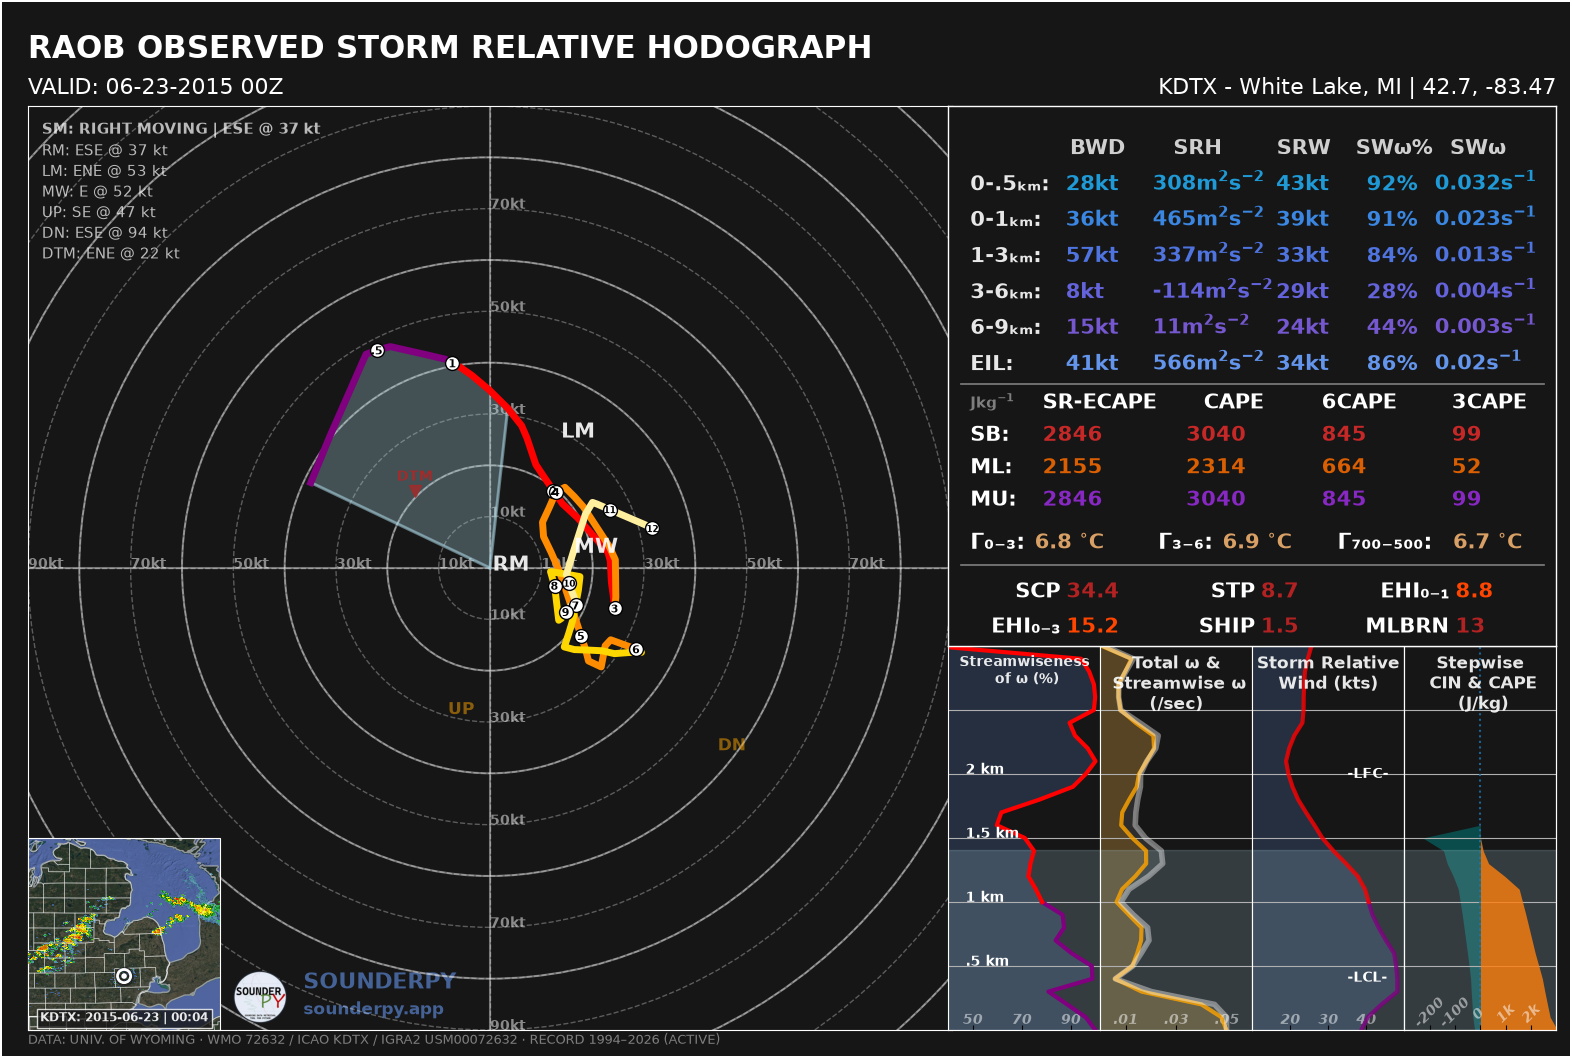

In [5]:
# storm-relative hodograph!
spy.build_hodograph(clean_data, dark_mode=True, sr_hodo=True, radar='single')

## Saving plots as a file

By default, SounderPy is set to show plots inline. If you want/need to save them to a file, SounderPy offers that option! 

Just set the `save` kwarg to True, and give it a file name using the `filename` kwarg! 

### IMPORTANT NOTE!!!

- If your plots come out with a funky layout when displaying them inline, it may be due to your screen resolution. 
- In the event that this is the case, simply use the `save=True` option to save plots to a file!

In [6]:
#spy.build_hodograph(clean_data, save=True, filename='sounderpy_2015062300z_DTX')